# Assignment DSC400 6.2

**Author:** Yisrael Wasserman  
**Date:** October 18, 2026  
**Description:** Machine Learning using Sklearn and Spark

### 1. Data Exploration and Cleaning
**Outcome:** No major data-cleaning issues were identified.

- Examined 10,000 customer records with four original columns.
- No null values, empty strings, or invalid negative values.
- Found 19 duplicate rows but retained them because different customers could share identical values.
- Approximately 20% of customers churned (1,967 out of 10,000).
- Three service types with similar customer counts and pricing ranges.
- Tenure ranged from 1–71 months; monthly charges ranged from $30–$120.

### 2. Spark SQL, Aggregations, and Visualization
**Outcome:** No clear relationship was identified between service type, tenure, and monthly charges.

- Used Spark SQL to calculate counts, averages, minimums, maximums, and ranges.
- Compared pricing and tenure across service types.
- Visualized average monthly charges by tenure, including sample counts.
- Used three-month moving averages to compare pricing trends across service types.
- Average charges remained relatively stable, with no clear trend across tenure or service types.

### 3. Feature Engineering
**Outcome:** Additional features did not noticeably improve predictions.

- Encoded churn and service type into numeric values.
- Created two additional features:
  - **Short_Tenure:** Customers with tenure of 12 months or less.
  - **Cost_High:** Customers paying above the 75th percentile for their service type.
- Compared model performance before and after adding these features.

### 4. Scikit-learn Models
**Outcome:** None of the models produced reliable predictions.

- Tested Logistic Regression, Decision Tree, Random Forest, and Gradient Boosting.
- Validation ROC-AUC scores remained around 0.50, indicating performance similar to random guessing.
- Used cross-validation to compare training and validation performance.
- **Logistic Regression and Decision Tree:** Poor performance with little evidence of overfitting.
- **Random Forest and Gradient Boosting:** Significant overfitting, with Random Forest achieving 1.00 training AUC but approximately 0.49 validation AUC.
- Tuned Random Forest to reduce overfitting. The training-validation gap decreased, but validation AUC remained around 0.49.
- The tuned model predicted both churn and no churn, but still struggled to distinguish them accurately.

### 5. Spark MLlib
**Outcome:** Spark Logistic Regression also failed to predict churn reliably.

- Trained a Logistic Regression model using Spark MLlib, with encoded features and a training/test split.
- The model predicted **no churn for every customer**, failing to identify any of the 370 actual churn cases.
- Accuracy was approximately 81%, but this was misleading due to class imbalance. Churn recall was 0%, indicating that the model was ineffective at identifying customers likely to leave.

### 6. Final Conclusion
- Neither Scikit-learn nor Spark MLlib produced reliable churn predictions.
- Feature engineering and model optimization did not meaningfully improve performance.
- The available features appear to contain little predictive signal, suggesting that additional customer information may be necessary.

## 1. Data Exploration: 

In [1]:
import pandas as pd
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="pyspark.sql.pandas.conversion")
df = pd.read_csv('telecom_customer_churn.csv')

In [2]:
df.head()

,Tenure,Monthly_Charges,Service_Type,Churn
0,67,115.41,Internet,No
1,55,97.76,Multiple,No
2,62,52.84,Phone,No
3,18,40.86,Multiple,No
4,56,81.29,Phone,No


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Tenure           10000 non-null  int64  
 1   Monthly_Charges  10000 non-null  float64
 2   Service_Type     10000 non-null  str    
 3   Churn            10000 non-null  str    
dtypes: float64(1), int64(1), str(2)
memory usage: 312.6 KB


- 10k entries
- No null data
- All dtypes seem correct, although Churn should be converted to a boolean.

In [4]:

import pandas as pd

# Only check original columns
cols = ["Tenure", "Monthly_Charges", "Service_Type", "Churn"]
data = df[cols]

# 1. Missing values
print("NULL VALUES")
print(data.isnull().sum())

# 2. Empty strings and whitespace
print("\nEMPTY STRINGS")
for col in ["Service_Type", "Churn"]:
    print(col, (data[col].str.strip() == "").sum())

# 3. Duplicate rows
print("\nDUPLICATES")
print("Duplicate rows:", data.duplicated().sum())

# 4. Invalid numeric values
print("\nINVALID VALUES")
print("Negative tenure:", (data["Tenure"] < 0).sum())
print("Negative charges:", (data["Monthly_Charges"] < 0).sum())


print("\nCHURN VALUES")
print(data["Churn"].value_counts(dropna=False))


NULL VALUES
Tenure             0
Monthly_Charges    0
Service_Type       0
Churn              0
dtype: int64

EMPTY STRINGS
Service_Type 0
Churn 0

DUPLICATES
Duplicate rows: 19

INVALID VALUES
Negative tenure: 0
Negative charges: 0

CHURN VALUES
Churn
No     8033
Yes    1967
Name: count, dtype: int64


- No null values were found.
- Only 19 duplicate rows were found among the 10,000 records. This is relatively low, considering that different customers could have identical values, especially if they joined during the same month. 
- The distribution of service types is fairly even.
- Approximately 20% of customers churn.
- No significant data cleaning appears necessary, so I will leave the DataFrame unchanged.

In [18]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.types import *
spark = SparkSession.builder.appName("SQL").getOrCreate()
spark_df = spark.createDataFrame(df)
spark_df.createOrReplaceTempView("tel")

# get count for each service type 
spark.sql("""
    SELECT Service_Type, COUNT(*) AS total
    FROM tel
    GROUP BY Service_Type
    ORDER BY total DESC
""").show()



+------------+-----+
|Service_Type|total|
+------------+-----+
|    Multiple| 4007|
|    Internet| 3015|
|       Phone| 2978|
+------------+-----+



In [6]:
spark.sql("""
    SELECT
        MIN(Tenure) AS min_tenure,
        MAX(Tenure) AS max_tenure,
        MAX(Tenure) - MIN(Tenure) AS tenure_range,
        MIN(Monthly_Charges) AS min_charge,
        MAX(Monthly_Charges) AS max_charge,
        MAX(Monthly_Charges) - MIN(Monthly_Charges) AS charge_range
    FROM tel
""").show()

+----------+----------+------------+----------+----------+------------+
|min_tenure|max_tenure|tenure_range|min_charge|max_charge|charge_range|
+----------+----------+------------+----------+----------+------------+
|         1|        71|          70|     30.01|     120.0|       89.99|
+----------+----------+------------+----------+----------+------------+



- Both Tenure and Charge range is wide. 
- We can try to split by Service type to see if charges are corrilated to the service or if there is other variables in play. 

In [7]:
spark.sql("""
    SELECT
        Service_Type,
        MIN(Tenure) AS min_tenure,
        MAX(Tenure) AS max_tenure,
        MAX(Tenure) - MIN(Tenure) AS tenure_range,
        MIN(Monthly_Charges) AS min_charge,
        MAX(Monthly_Charges) AS max_charge,
        MAX(Monthly_Charges) - MIN(Monthly_Charges) AS charge_range,
        AVG(Monthly_Charges) AS avg_charge,
        COUNT(*) AS sample_count
    FROM tel
    GROUP BY Service_Type
    ORDER BY Service_Type
""").show()

+------------+----------+----------+------------+----------+----------+-----------------+-----------------+------------+
|Service_Type|min_tenure|max_tenure|tenure_range|min_charge|max_charge|     charge_range|       avg_charge|sample_count|
+------------+----------+----------+------------+----------+----------+-----------------+-----------------+------------+
|    Internet|         1|        71|          70|     30.03|     120.0|            89.97|74.86951243781093|        3015|
|    Multiple|         1|        71|          70|     30.04|    119.99|89.94999999999999|74.89853755927128|        4007|
|       Phone|         1|        71|          70|     30.01|    119.98|            89.97|75.22099395567496|        2978|
+------------+----------+----------+------------+----------+----------+-----------------+-----------------+------------+



It seems they all have the same ranges for both price and tenure. 

- This disproves my thoery that price is soley based on service type.
- One possiblity is that its by usage, and there is a min price. (But I won't make any assumptions at this point)

In [8]:
# lets veiw the avg price by Tenure: 

avg_df = spark.sql("""
    SELECT
        Tenure,
        ROUND(AVG(Monthly_Charges), 2) AS avg_monthly_charge,
        COUNT(*) AS sample_count
    FROM tel
    GROUP BY Tenure
    ORDER BY Tenure
""")

avg_df.show(10)

+------+------------------+------------+
|Tenure|avg_monthly_charge|sample_count|
+------+------------------+------------+
|     1|             71.88|         149|
|     2|             72.33|         169|
|     3|             77.39|         136|
|     4|             74.35|         141|
|     5|             78.92|         163|
|     6|             71.48|         147|
|     7|             75.58|         137|
|     8|             74.58|         144|
|     9|             76.12|         148|
|    10|             76.97|         129|
+------+------------------+------------+
only showing top 10 rows


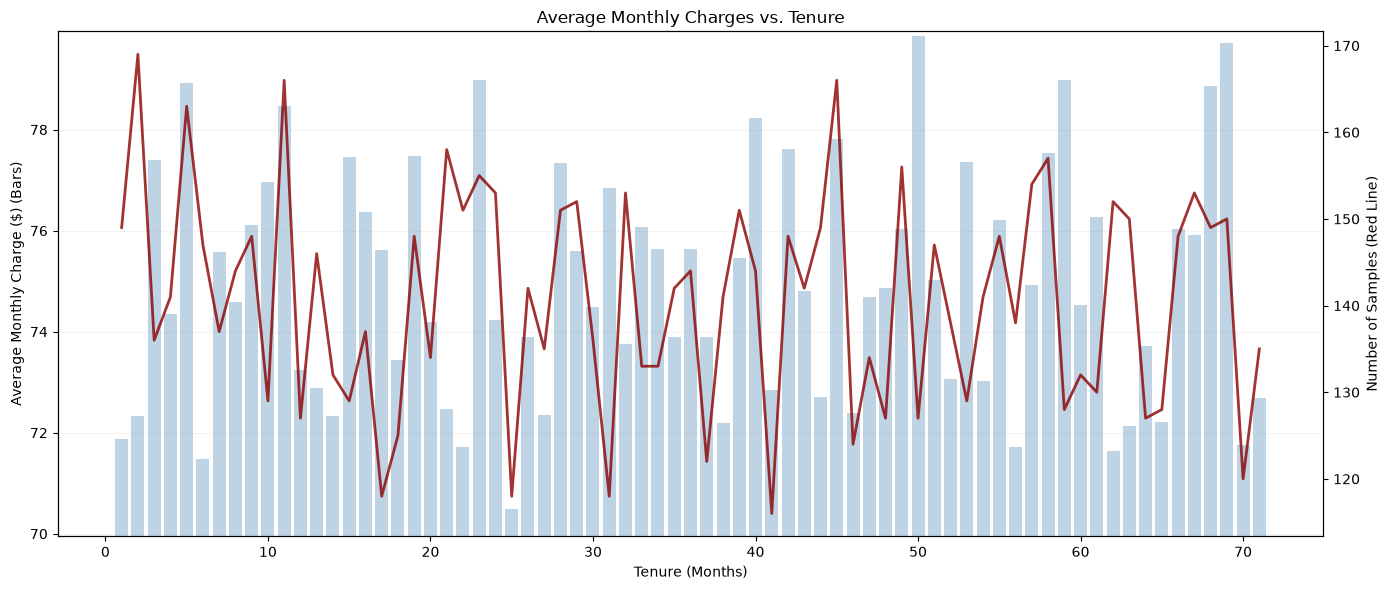

In [9]:
# plt average price by tenure with sample count for validity: 

import matplotlib.pyplot as plt

pdf = avg_df.toPandas()

fig, ax1 = plt.subplots(figsize=(14, 6))

# Average charges as lighter bars
ax1.bar(
    pdf["Tenure"],
    pdf["avg_monthly_charge"],
    color="steelblue",
    alpha=0.35,
    width=0.8
)

# Zoom in to +/- $5 around the overall mean
center = pdf["avg_monthly_charge"].mean()
ax1.set_ylim(center - 5, center + 5)

ax1.set_xlabel("Tenure (Months)")
ax1.set_ylabel("Average Monthly Charge ($) (Bars)")
ax1.grid(axis="y", alpha=0.15)

# Sample count as a line
ax2 = ax1.twinx()

ax2.plot(
    pdf["Tenure"],
    pdf["sample_count"],
    color="darkred",
    linewidth=2,
    alpha=0.8,
    label="Sample Count (Red Line)"
)

ax2.set_ylabel("Number of Samples (Red Line)")

plt.title("Average Monthly Charges vs. Tenure")
plt.tight_layout()
plt.show()

- Average Monthly charge seems somewhat stable across all tenures, with it ranging from 71-79
- Sample size is also pretty stable from 120-170.
- There might be some slight corrilation between lower sample sizing and lower average monthly cost by tenure. But its hard to tell, and there are some exceptions. 

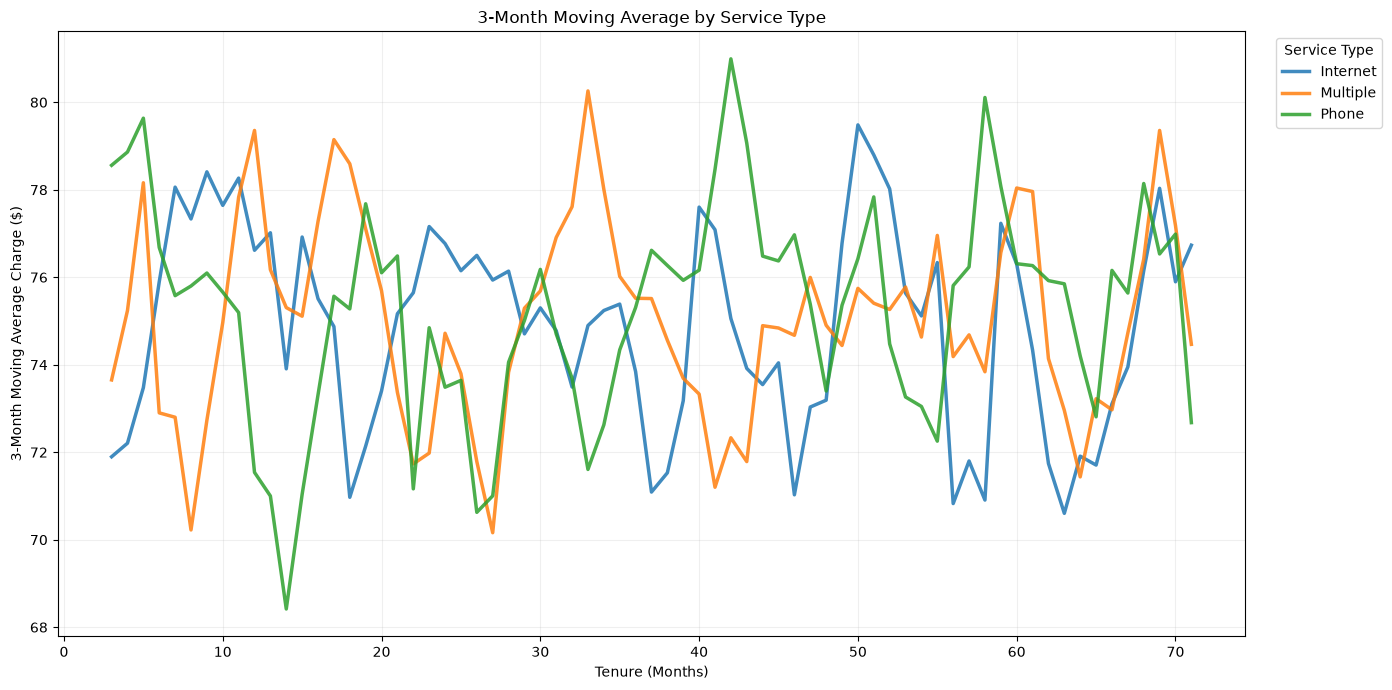

In [10]:
# Now lets plt average cost per service by tenure 

avg_df = spark.sql("""
    SELECT
        Service_Type,
        Tenure,
        ROUND(AVG(Monthly_Charges), 2) AS avg_charge,
        COUNT(*) AS sample_count
    FROM tel
    GROUP BY Service_Type, Tenure
    ORDER BY Service_Type, Tenure
""")

import matplotlib.pyplot as plt

pdf = avg_df.toPandas()

fig, ax = plt.subplots(figsize=(14, 7))

for service, group in pdf.groupby("Service_Type"):
    group = group.sort_values("Tenure").copy()

    # 3-Month moving average
    group["MA3"] = group["avg_charge"].rolling(
        window=3,
        min_periods=3
    ).mean()

    ax.plot(
        group["Tenure"],
        group["MA3"],
        linewidth=2.5,
        alpha=0.85,
        label=service
    )

ax.set_xlabel("Tenure (Months)")
ax.set_ylabel("3-Month Moving Average Charge ($)")
ax.set_title("3-Month Moving Average by Service Type")

ax.legend(
    title="Service Type",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

- There dosen't seem to be any pattern or clear trend in any single service type over time.
- I used a three-month moving average to smooth out monthly fluctuations and make the overall trends easier to see. A larger window would provide more smoothing but could hide shorter-term changes, so three months seemed like a reasonable balance.

## 2. Sklearn models

- **Problem type:** Binary classification, predicting whether a customer will churn (Yes or No).
- **Class distribution:** Approximately 20% of customers churn.
- **Model priorities:** We may want to prioritize **recall**, identifying as many customers likely to churn as possible, even if we incorrectly flag some customers who would stay. This makes sense if we plan to offer promotions to encourage at-risk customers to remain.
- **Alternative approach:** If promotions are expensive, we may instead prioritize **precision**, ensuring that a higher percentage of customers receiving promotions are actually at risk of churning.

In [11]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

df['Churn enc'] = le.fit_transform(df['Churn'])
df['Service_Type enc'] = le.fit_transform(df['Service_Type'])
print("Count of churn 1:", len(df[df['Churn enc'] == 1]))
print("Count of churn 0:", len(df[df['Churn enc'] == 0]))

# removing extra columns ( non encoded columns) 
training_df = df.drop(columns=['Service_Type','Churn'])
print("Columns in training_df: ",training_df.columns)


Count of churn 1: 1967
Count of churn 0: 8033
Columns in training_df:  Index(['Tenure', 'Monthly_Charges', 'Churn enc', 'Service_Type enc'], dtype='str')


we can see that churn happens ~20% of the time

In [12]:

from sklearn.model_selection import train_test_split, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
import pandas as pd

# Features and target
X = training_df.drop(columns=["Churn enc"])
y = training_df["Churn enc"].astype(int)

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# Preprocessing
numeric_features = X.select_dtypes(include="number").columns.drop(
    "Service_Type enc"
).tolist()

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ), ["Service_Type enc"])
])

# Models
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=5, random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, random_state=42
    ),
    "Gradient Boosting": HistGradientBoostingClassifier(
        random_state=42
    )
}

# Evaluate models
results = []

for name, model in models.items():
    pipeline = make_pipeline(preprocessor, model)

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=5,
        scoring=["roc_auc", "f1", "precision", "recall"]
    )

    results.append({
        "Model": name,
        "ROC_AUC": scores["test_roc_auc"].mean(),
        "F1": scores["test_f1"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean()
    })

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        "ROC_AUC", ascending=False
    ).round(4)
)


/Users/yisraelwasserman/Projects/dsc400-yis0/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/yisraelwasserman/Projects/dsc400-yis0/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/yisraelwasserman/Projects/dsc400-yis0/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(averag

,Model,ROC_AUC,F1,Precision,Recall
2,Random Forest,0.4999,0.1374,0.2005,0.1048
3,Gradient Boosting,0.4988,0.0160,0.2708,0.0083
1,Decision Tree,0.4988,0.0049,0.0971,0.0025
0,Logistic Regression,0.4766,0.0000,0.0000,0.0000


### Model Evaluation

**Best-performing model: Random Forest**

**Observations:**

- **Random Forest performed best** among the models tested, although its performance is still very poor.
- **ROC-AUC is approximately 0.50**, meaning the model is no better than random guessing at distinguishing customers who churn from those who don't. 
- **Precision is 20%**, meaning that of all customers predicted to churn, only 20% actually churned. Since the overall churn rate is also 20%, the model provides little improvement over randomly selecting customers.
- **Recall is 10.48%**, meaning the model correctly identifies only about 10 out of every 100 customers who actually churn.
- **F1 is 0.1374**, indicating a poor balance between precision and recall.

**Conclusion:**

The Random Forest model is not effectively predicting customer churn. Its ROC-AUC suggests that the available features provide little useful predictive information.

**Next step:** Investigate whether adding features can imporve the model

## 2.b Feature engenieering: 

Lets see if adding features will improve the model: 

1. **Short Tenure:** Identifies customers who have been with the company for 12 months or less. This feature assumes that newer customers may be more likely to churn.

2. **High Cost:** Identifies customers whose monthly charges are above the 75th percentile for their service type. This feature assumes that customers paying relatively high prices may be more likely to churn.

In [13]:

# Short tenure: 12 months or less
training_df["Short_Tenure"] = (training_df["Tenure"] <= 12).astype(int)

# High cost: above the 75th percentile for each service type
training_df["Cost_High"] = (
    training_df["Monthly_Charges"] >
    training_df.groupby("Service_Type enc")["Monthly_Charges"].transform(
        lambda x: x.quantile(0.75)
    )
).astype(int)

training_df.head()


,Tenure,Monthly_Charges,Churn enc,Service_Type enc,Short_Tenure,Cost_High
0,67,115.41,0,0,0,1
1,55,97.76,0,1,0,1
2,62,52.84,0,2,0,0
3,18,40.86,0,1,0,0
4,56,81.29,0,2,0,0


In [14]:

from sklearn.model_selection import train_test_split, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
import pandas as pd

# Features and target
X = training_df.drop(columns=["Churn enc"])
y = training_df["Churn enc"].astype(int)

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

# Preprocessing
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), [
        "Tenure", "Monthly_Charges", "Short_Tenure"
    ]),
    ("cat", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ), ["Service_Type enc"])
])

# Models
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=5, random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, random_state=42
    ),
    "Gradient Boosting": HistGradientBoostingClassifier(
        random_state=42
    )
}

# Evaluate with cross-validation
results = []

for name, model in models.items():
    pipeline = make_pipeline(preprocessor, model)

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=5,
        scoring=["roc_auc", "f1", "precision", "recall"]
    )

    results.append({
        "Model": name,
        "ROC_AUC": scores["test_roc_auc"].mean(),
        "F1": scores["test_f1"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean()
    })

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        "ROC_AUC", ascending=False
    ).round(4)
)


/Users/yisraelwasserman/Projects/dsc400-yis0/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/yisraelwasserman/Projects/dsc400-yis0/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/yisraelwasserman/Projects/dsc400-yis0/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(averag

,Model,ROC_AUC,F1,Precision,Recall
2,Random Forest,0.4992,0.1395,0.1934,0.1093
1,Decision Tree,0.4989,0.0049,0.1071,0.0025
3,Gradient Boosting,0.4988,0.0160,0.2708,0.0083
0,Logistic Regression,0.4808,0.0000,0.0000,0.0000


I see no noticeable difference in the results after adding more features.

This suggests that either the available training data doesn't contain enough information to accurately predict churn, or the models need further tuning.

My next step is to check whether the models are overfitting or underfitting.

In [15]:

from sklearn.model_selection import cross_validate
from sklearn.pipeline import make_pipeline
import pandas as pd

results = []

for name, model in models.items():
    pipeline = make_pipeline(preprocessor, model)

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=5,
        scoring="roc_auc",
        return_train_score=True
    )

    results.append({
        "Model": name,
        "Train_AUC": scores["train_score"].mean(),
        "Validation_AUC": scores["test_score"].mean(),
        "Gap": (
            scores["train_score"].mean()
            - scores["test_score"].mean()
        )
    })

display(pd.DataFrame(results).round(4))


,Model,Train_AUC,Validation_AUC,Gap
0,Logistic Regression,0.5101,0.4808,0.0293
1,Decision Tree,0.5362,0.4989,0.0372
2,Random Forest,1.0000,0.4992,0.5008
3,Gradient Boosting,0.8352,0.4988,0.3364


Random Forest and Gradient Boosting are severely overfitting. Random Forest has a training AUC of 100% but a validation AUC of only 49%, while Gradient Boosting has a 33% point gap.

Logistic Regression and Decision Tree appear to be underfitting, or there may be no discernible predictive signal in the data.

In [16]:

from sklearn.model_selection import cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report
)

# Random Forest with reduced overfitting
rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=5,
    min_samples_split=20,
    min_samples_leaf=10,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

pipeline = make_pipeline(preprocessor, rf)

# Cross-validation
metrics = ["accuracy", "precision", "recall", "f1", "roc_auc"]

scores = cross_validate(
    pipeline,
    X_train,
    y_train,
    cv=5,
    scoring=metrics,
    return_train_score=True
)

# Compare training and validation metrics
results = pd.DataFrame({
    "Metric": metrics,
    "Train": [scores[f"train_{m}"].mean() for m in metrics],
    "Validation": [scores[f"test_{m}"].mean() for m in metrics]
})

results["Gap"] = results["Train"] - results["Validation"]

display(results.round(4))

# Train final model
pipeline.fit(X_train, y_train)

# Make predictions on test data
y_pred = pipeline.predict(X_test)
y_prob = pipeline.predict_proba(X_test)[:, 1]

# Test metrics
test_results = pd.DataFrame({
    "Metric": metrics,
    "Test": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, y_pred, zero_division=0),
        roc_auc_score(y_test, y_prob)
    ]
})


# Confusion Matrix
cm = pd.DataFrame(
    confusion_matrix(y_test, y_pred, labels=[0, 1]),
    index=["Actual No Churn", "Actual Churn"],
    columns=["Predicted No Churn", "Predicted Churn"]
)

display(cm)





,Metric,Train,Validation,Gap
0,accuracy,0.6084,0.5285,0.0799
1,precision,0.2825,0.1970,0.0855
2,recall,0.6434,0.4536,0.1898
3,f1,0.3925,0.2746,0.1180
4,roc_auc,0.6708,0.4947,0.1762


,Predicted No Churn,Predicted Churn
Actual No Churn,861,746
Actual Churn,215,178


- The gap between training and validation performance is much smaller, indicating reduced overfitting.
- However, validation performance has not improved significantly, with ROC-AUC remaining around 0.49.
- Precision, recall, and F1 have improved compared to the previous model, but overall predictive performance remains poor.
- The model now predicts both churn and no churn, but struggles to distinguish between them accurately.
- Overall, the model still performs roughly at the level of random guessing.

## 3.Spark Model 

In [17]:
from pyspark.sql import functions as F
from pyspark.ml import Pipeline
from pyspark.ml.feature import VectorAssembler, OneHotEncoder
from pyspark.ml.classification import LogisticRegression
from pyspark.ml.evaluation import (
    BinaryClassificationEvaluator,
    MulticlassClassificationEvaluator
)

#  Convert existing data to Spark
spark_df = spark.createDataFrame(training_df)

# Rename target column
spark_df = spark_df.withColumnRenamed("Churn enc", "label")

#  Train/test split
train, test = spark_df.randomSplit([0.8, 0.2], seed=42)

# 4. Encode service type and assemble features
encoder = OneHotEncoder(
    inputCols=["Service_Type enc"],
    outputCols=["Service_Vector"],
    handleInvalid="keep"
)

#  Assemble existing features
assembler = VectorAssembler(
    inputCols=[
        "Tenure",
        "Monthly_Charges",
        "Short_Tenure",
        "Cost_High",
        "Service_Vector"
    ],
    outputCol="features"
)

#  Train Logistic Regression
lr = LogisticRegression(
    featuresCol="features",
    labelCol="label",
    maxIter=100
)

pipeline = Pipeline(stages=[encoder, assembler, lr])
model = pipeline.fit(train)

#  Make predictions
predictions = model.transform(test).cache()

#  Evaluate
results = {}

results["ROC_AUC"] = BinaryClassificationEvaluator(
    labelCol="label",
    metricName="areaUnderROC"
).evaluate(predictions)

for metric in ["accuracy", "f1", "precisionByLabel", "recallByLabel"]:
    evaluator = MulticlassClassificationEvaluator(
        labelCol="label",
        predictionCol="prediction",
        metricName=metric,
        metricLabel=1.0
    )
    results[metric] = evaluator.evaluate(predictions)

# Display metrics
display(pd.DataFrame([results]).round(4))

# Confusion matrix
predictions.groupBy("label", "prediction").count().orderBy(
    "label", "prediction"
).show()

,ROC_AUC,accuracy,f1,precisionByLabel,recallByLabel
0,0.4879,0.8082,0.7225,0.0,0.0


+-----+----------+-----+
|label|prediction|count|
+-----+----------+-----+
|    0|       0.0| 1559|
|    1|       0.0|  370|
+-----+----------+-----+



Spark's main advantage is its ability to process large datasets efficiently through distributed computing. Switching to Spark did not improve predictive performance in this experiment.


### Final Conclusion

Overall, none of the models performed well, including Logistic Regression, Decision Tree, Random Forest, Gradient Boosting, and Spark's Logistic Regression.

Some models showed significant overfitting, with high training scores but validation AUC scores near 0.50. Other models showed little improvement over random guessing.

The final Spark model predicted 0 (no churn) for every customer. Although it achieved 80% accuracy, this is misleading because it failed to identify any customers who actually churned.

##### These results suggest that the models were unable to identify useful predictive patterns in the available features. However, the results alone do not establish whether this is due to weak relationships in the data, missing features, or other factors. 
